In [1]:
x=1

In [2]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt

/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx ins

In [14]:
adata = sc.read_h5ad('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil_reg/pbmc_scvi/6e49b5e194_adata_both.h5ad')
adata

AnnData object with n_obs × n_vars = 215678 × 30
    obs: 'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'full_clustering', 'initial_clustering', 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'split0', 'split1', 'split2', 'split3', 'split4', '_scvi_batch', '_scvi_labels', 'group', 'cell_attn_0', 'cell_attn_1', 'cell_attn_2', 'cell_attn_3', 'cell_attn_4', 'cell_attn'
    uns: 'Age_interval_colors', 'Collection_Day_colors', 'Days_from_onset_colors', 'Outcome_colors', 'Resample_colors', 'Sex_colors', 'Site_colors', 'Smoker_colors', 'Status_colors', 'Status_on_day_collection_colors', 'Status_on_day_collection_summary_colors', 'Swab_result_colors', 'Worst_Clinical_Status_colors', 'full_clustering_colors', 'initial_clustering_colors', 'neighbors

In [15]:
ct_df = adata.obs[['Status_on_day_collection_summary', 'initial_clustering']]
ct_df_group = ct_df.groupby('Status_on_day_collection_summary').value_counts(normalize=True).mul(100)
ct_df_group = ct_df_group.unstack().reindex(['Healthy', 'Mild', 'Severe']).T

/tmp/ipykernel_1249341/3767983853.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_df_group = ct_df.groupby('Status_on_day_collection_summary').value_counts(normalize=True).mul(100)


In [16]:
ct_df_group['Mild - Healthy'] = (ct_df_group['Mild'] - ct_df_group['Healthy']) / ct_df_group['Healthy']
ct_df_group['Severe - Healthy'] = (ct_df_group['Severe'] - ct_df_group['Healthy']) / ct_df_group['Healthy']
ct_df_group['Severe - Mild'] = (ct_df_group['Severe'] - ct_df_group['Mild']) / ct_df_group['Mild']
ct_df_group

Status_on_day_collection_summary,Healthy,Mild,Severe,Mild - Healthy,Severe - Healthy,Severe - Mild
initial_clustering,,,,,,
B_cell,7.764797,10.613397,11.691050,0.366861,0.505648,0.101537
CD4,30.196238,24.407099,20.337316,-0.191717,-0.326495,-0.166746
CD8,18.946105,14.057488,14.178752,-0.258028,-0.251627,0.008626
CD14,9.997176,18.917111,17.498243,0.892245,0.750319,-0.075004
CD16,3.134155,4.007579,1.963841,0.278680,-0.373407,-0.509968
DCs,1.995906,1.390764,0.727017,-0.303192,-0.635746,-0.477253
HSC,0.146472,0.242733,1.020891,0.657197,5.969854,3.205809
Lymph_prolif,0.308827,1.330080,1.308375,3.306876,3.236594,-0.016319
MAIT,2.105319,1.202521,0.512362,-0.428817,-0.756635,-0.573927


In [17]:
adata.obs['initial_clustering'].value_counts()

initial_clustering
CD4             52736
CD14            34635
CD8             33184
NK_16hi         30798
B_cell          22120
CD16             6549
Platelets        5885
gdT              5009
Treg             4572
NK_56hi          4364
Plasmablast      3856
DCs              2823
MAIT             2565
pDC              2405
Lymph_prolif     2273
HSC              1078
RBC               652
Mono_prolif       174
Name: count, dtype: int64

In [18]:
# remove cell types with less than 1000 cells
ct_df_group = ct_df_group.drop(['RBC', 'Mono_prolif'])

In [19]:
ct_df_group

Status_on_day_collection_summary,Healthy,Mild,Severe,Mild - Healthy,Severe - Healthy,Severe - Mild
initial_clustering,,,,,,
B_cell,7.764797,10.613397,11.691050,0.366861,0.505648,0.101537
CD4,30.196238,24.407099,20.337316,-0.191717,-0.326495,-0.166746
CD8,18.946105,14.057488,14.178752,-0.258028,-0.251627,0.008626
CD14,9.997176,18.917111,17.498243,0.892245,0.750319,-0.075004
CD16,3.134155,4.007579,1.963841,0.278680,-0.373407,-0.509968
DCs,1.995906,1.390764,0.727017,-0.303192,-0.635746,-0.477253
HSC,0.146472,0.242733,1.020891,0.657197,5.969854,3.205809
Lymph_prolif,0.308827,1.330080,1.308375,3.306876,3.236594,-0.016319
MAIT,2.105319,1.202521,0.512362,-0.428817,-0.756635,-0.573927


In [20]:
ct_df_group.sort_values('Mild - Healthy')

Status_on_day_collection_summary,Healthy,Mild,Severe,Mild - Healthy,Severe - Healthy,Severe - Mild
initial_clustering,,,,,,
gdT,4.383581,2.147448,1.010669,-0.510116,-0.769442,-0.529363
MAIT,2.105319,1.202521,0.512362,-0.428817,-0.756635,-0.573927
DCs,1.995906,1.390764,0.727017,-0.303192,-0.635746,-0.477253
Platelets,2.523559,1.815547,3.819076,-0.280561,0.513369,1.103540
CD8,18.946105,14.057488,14.178752,-0.258028,-0.251627,0.008626
CD4,30.196238,24.407099,20.337316,-0.191717,-0.326495,-0.166746
Treg,2.534147,2.128872,1.810516,-0.159926,-0.285552,-0.149542
NK_56hi,2.276497,2.184601,1.673801,-0.040367,-0.264747,-0.233819
NK_16hi,12.480147,12.726169,17.185204,0.019713,0.377003,0.350383


In [21]:
ct_df_group.sort_values('Severe - Healthy')

Status_on_day_collection_summary,Healthy,Mild,Severe,Mild - Healthy,Severe - Healthy,Severe - Mild
initial_clustering,,,,,,
gdT,4.383581,2.147448,1.010669,-0.510116,-0.769442,-0.529363
MAIT,2.105319,1.202521,0.512362,-0.428817,-0.756635,-0.573927
DCs,1.995906,1.390764,0.727017,-0.303192,-0.635746,-0.477253
CD16,3.134155,4.007579,1.963841,0.278680,-0.373407,-0.509968
CD4,30.196238,24.407099,20.337316,-0.191717,-0.326495,-0.166746
Treg,2.534147,2.128872,1.810516,-0.159926,-0.285552,-0.149542
NK_56hi,2.276497,2.184601,1.673801,-0.040367,-0.264747,-0.233819
CD8,18.946105,14.057488,14.178752,-0.258028,-0.251627,0.008626
NK_16hi,12.480147,12.726169,17.185204,0.019713,0.377003,0.350383


In [22]:
df = ct_df_group.loc[['Plasmablast', 'HSC', 'Lymph_prolif']]

In [23]:
sc.set_figure_params(vector_friendly=True, figsize=(4,2), dpi=300)

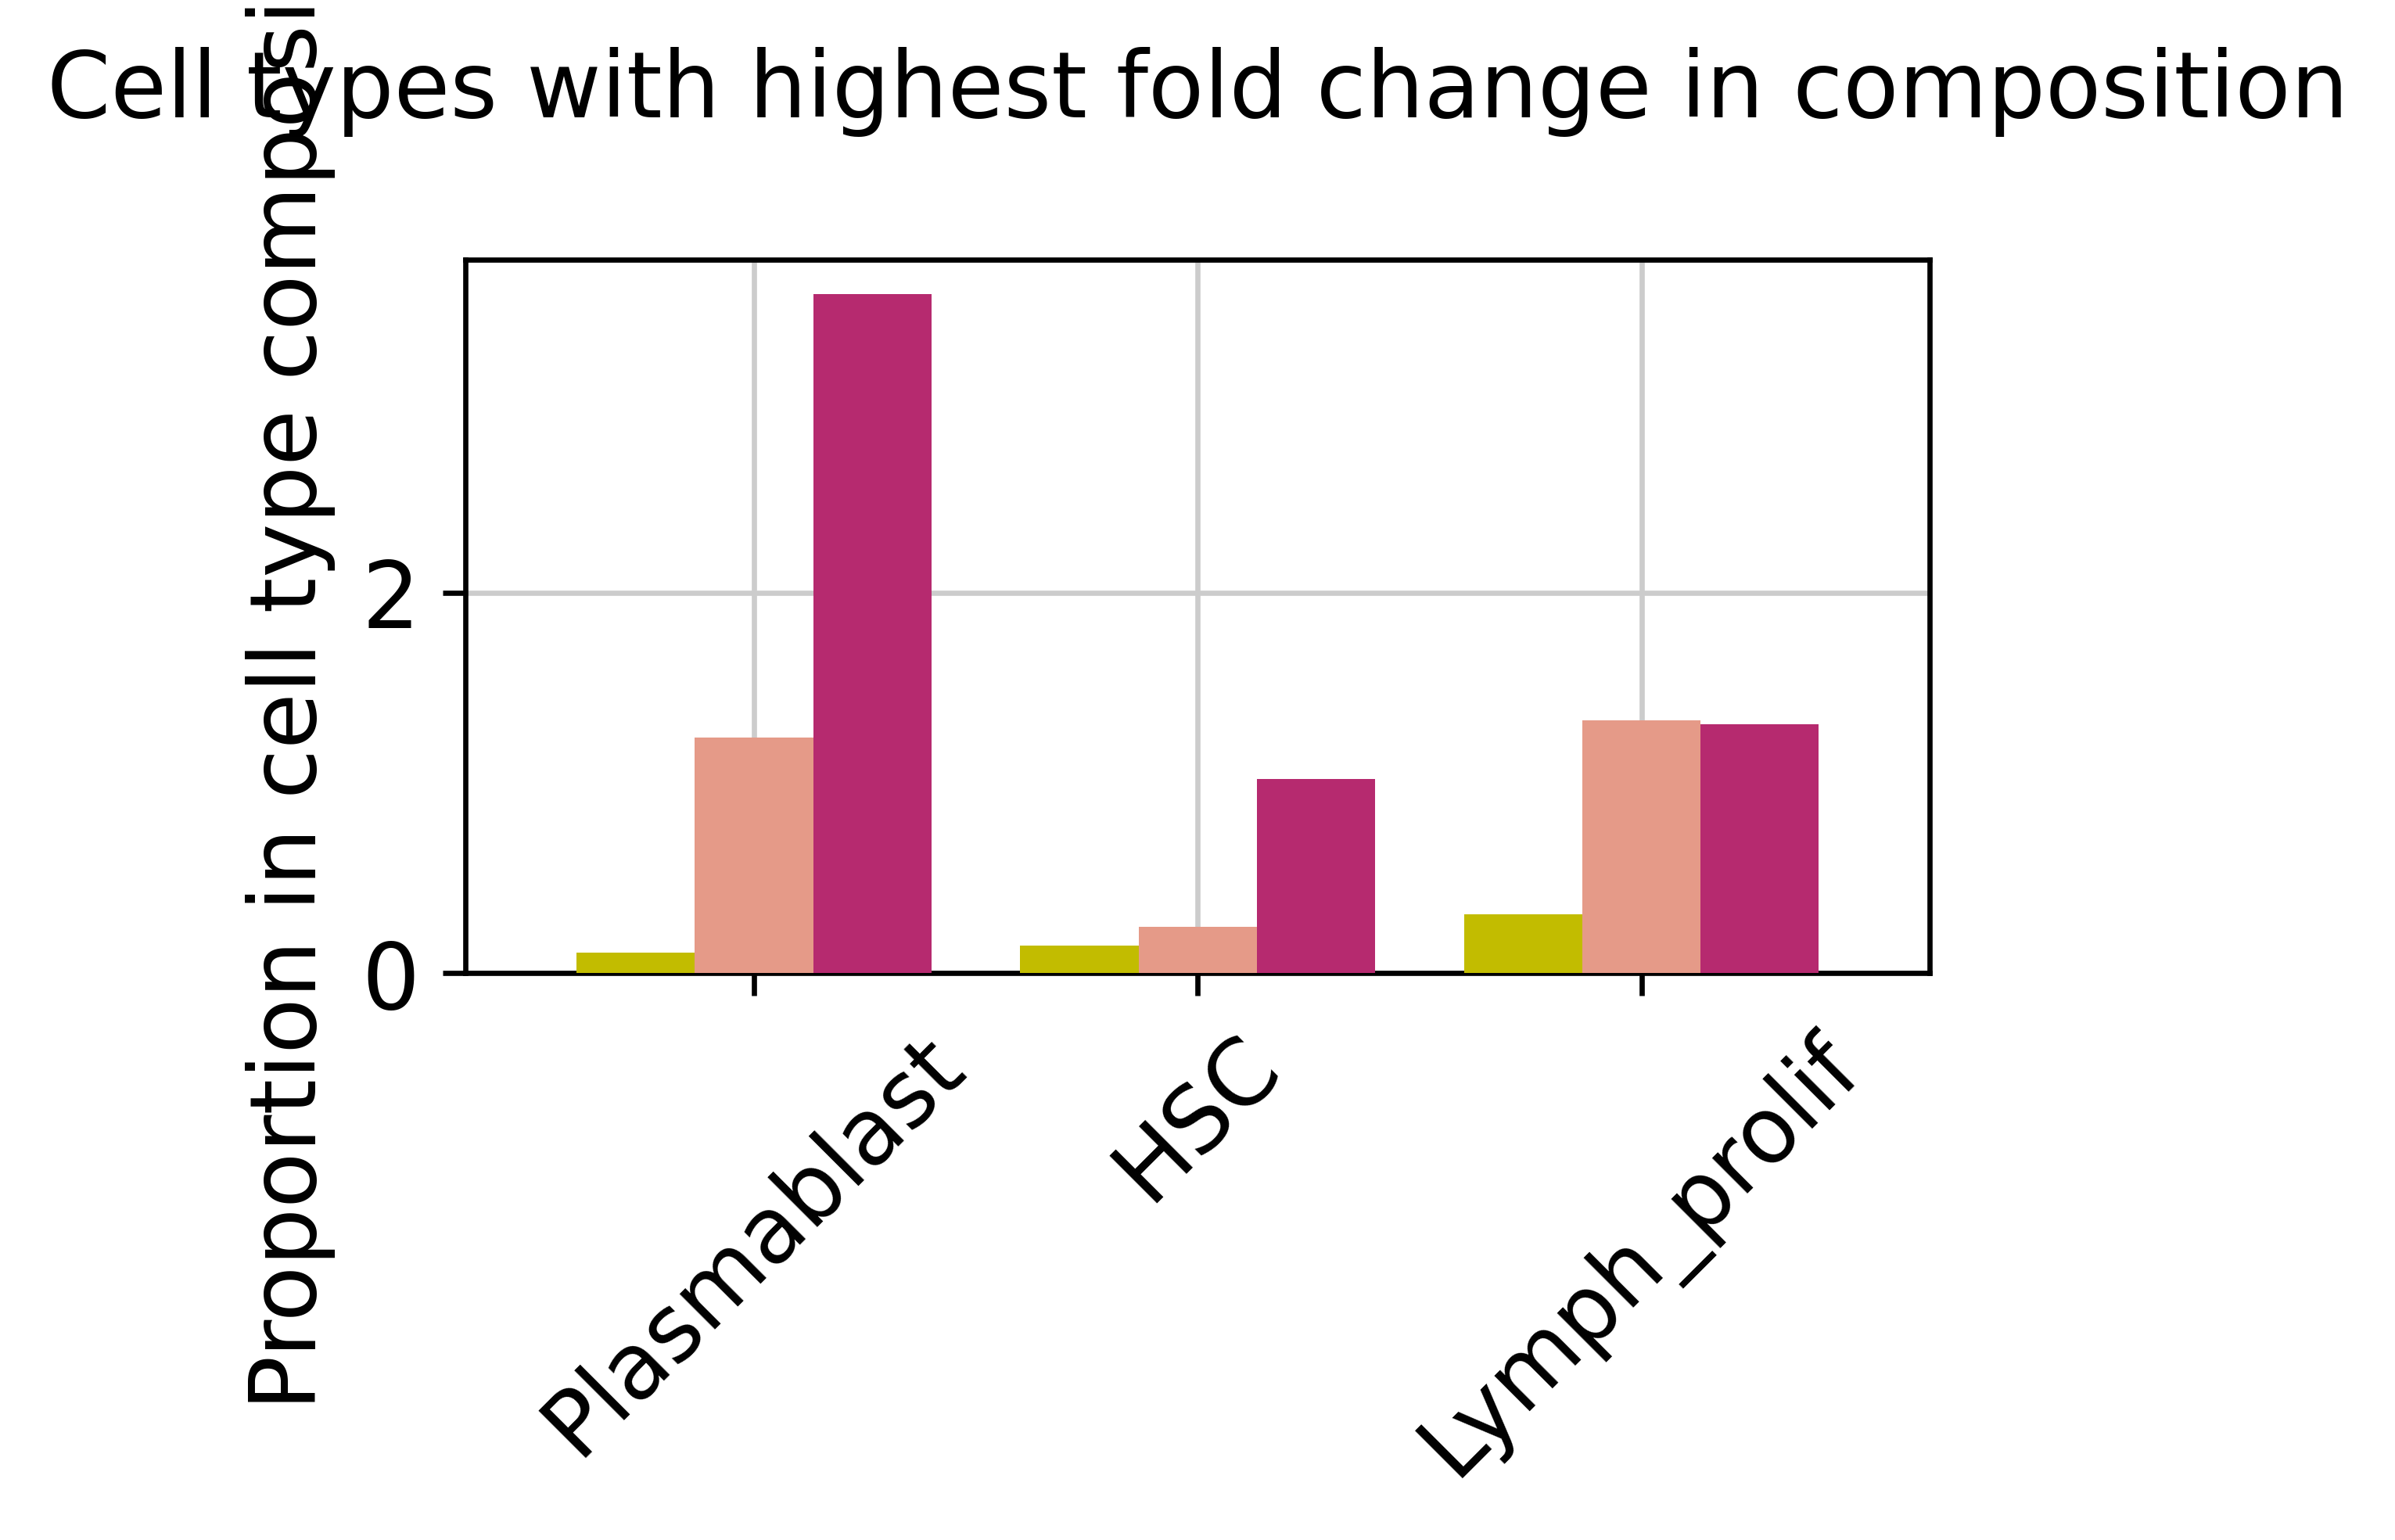

In [24]:
fig, ax = plt.subplots(1, 1)
ax.grid(zorder=0)
df[['Healthy', 'Mild', 'Severe']].plot.bar(color=['#C2BC00', '#E59A88', '#B62A6F'], rot=45, legend=False, ax=ax, zorder=3, width=0.8)
plt.title('Cell types with highest fold change in composition\n')
plt.xlabel('')
plt.ylabel('Proportion in cell type composition')
plt.savefig('figures/bar_pbmc_proportions.svg', bbox_inches='tight')